# 關鍵詞辨識：這段手語裡出現了哪些詞？

不再逐字產生整句中文，改成判斷**「這段手語有沒有出現某些常見詞」**：
用 jieba 把字幕斷詞，選出訓練集最常見的 `N_KEYWORDS` 個詞 (例如「昨天」「台灣」「總統」「天氣」)，
模型對每個詞輸出「有出現」的機率。

- **好處**：不用排出中文語序 (字幕是翻譯，跟手語語序不同)；常見詞出現次數多，資料相對充足
- **模型**：跟之前一樣的 encoder (含缺漏遮罩、資料增強)，把 decoder 換成一個分類層
- **一次跑兩個版本**：`手+臉` (292 維) 與 `只有手` (把臉部特徵全部遮掉)，用同一份資料比較臉部特徵的效果
- 每個版本跑完就存檔；中途中斷重新執行，已完成的版本會自動略過

**評估指標**

| 指標 | 意思 |
|---|---|
| **mAP** (平均精確度) | 每個詞把測試句子依機率排序，正確的句子排得越前面越好；0～1，越高越好。所有詞取平均 |
| 基準：亂猜 | 隨機排序的 mAP，約等於每個詞的出現比例 |
| 基準：同則新聞內打亂 | 把預測在同一則新聞的句子之間打亂。模型如果只認得「新聞主題」，打亂後分數不會掉；**真的辨認出這句的手勢，打亂後分數才會明顯下降** |
| F1 | 每個詞用驗證集挑出最佳門檻，再套到測試集，算「預測出現」跟「真的出現」的吻合程度 |

**執行前**：要先完成臉部流程 (`03segments_face`)，跟 `sign_transformer_face.ipynb` 用的資料相同。
第一次執行需要 `pip install jieba`，繁體詞典 `dict.txt.big` 找不到時會自動下載到 `data/`。

In [1]:
import copy
import csv
import json
import math
import random
import re
import urllib.request
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

warnings.filterwarnings("ignore")
# os.chdir(r"C:\你的專案資料夾\Data Training")

# ================================================================ 路徑設定
SEG_TAG = "_face"          # 分段資料：03segments_face / 03labels_face (292 維)
LABEL_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03labels" + SEG_TAG)
SEG_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03segments" + SEG_TAG)
DATA_DIR = Path(r"data")                     # 沿用原本的資料切分 (句子跟其他 notebook 一一對應)
OUT_DIR = Path(r"keyword")                   # 底下每個版本一個資料夾
JIEBA_DICT = DATA_DIR / "dict.txt.big"       # jieba 繁體詞典，找不到會自動下載
JIEBA_DICT_URL = "https://raw.githubusercontent.com/fxsjy/jieba/master/extra_dict/dict.txt.big"

# ================================================================ 關鍵詞設定
N_KEYWORDS = 200           # 取訓練集最常見的幾個詞
MIN_WORD_LEN = 2           # 至少幾個字 (單字太模糊，例如「的」「是」)
STOPWORDS = set()          # 想排除的詞，例如 {"表示", "已經"}
MIN_TEST_POSITIVE = 3      # 測試集至少出現幾次的詞才算進 mAP (太少的話分數不穩定)

# ================================================================ 要比較的版本
VARIANTS = {               # 名稱: 是否使用臉部特徵
    "手+臉": True,
    "只有手": False,
}

# ================================================================ 資料 (跟 face notebook 相同)
SPLIT = (0.8, 0.1, 0.1)
SEED = 42
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
MIN_FREQ = 2
FEAT_DIM = 292
FLAG_DIMS = [126, 127, 155, 291]
USE_BLENDSHAPES = USE_LIPS = USE_HEAD_POSE = True   # 由 VARIANTS 自動切換，不用手動改
FRAME_STRIDE = 2
MAX_FRAMES = 300
MAX_TEXT_LEN = 64
SPEED_RANGE = (0.8, 1.2)
NOISE_STD = 0.05
NORM_FILE = "norm_masked_face.npz"
AUGMENT = True
ROTATE_DEG = 10
SCALE_RANGE = (0.9, 1.1)
SHIFT = 0.05
TIME_MASK_N = 2
TIME_MASK_MAX = 0.1

# ================================================================ 模型與訓練
D_MODEL = 256
N_HEADS = 4
ENC_LAYERS = 4
FF_DIM = 1024
DROPOUT = 0.3
BATCH_SIZE = 32
EPOCHS = 150
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 5
PATIENCE = 10              # val mAP 連續幾個 epoch 沒進步就停止
MAX_POS_WEIGHT = 10.0      # 少見的詞提高正例權重的上限

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
PAD, BOS, EOS, UNK = 0, 1, 2, 3
print("device:", DEVICE)

device: cuda


## DATASET
跟 face notebook 相同：沿用 `data/` 的資料切分，檢查分段檔是否齊全，`norm_masked_face.npz` 已存在就直接沿用。

In [2]:
if all((DATA_DIR / name).exists() for name in ("train.csv", "val.csv", "test.csv", "vocab.json", "norm.npz")):
    print(f"沿用 {DATA_DIR} 裡現有的資料切分、字典與 norm")
else:
    print(f"{DATA_DIR} 沒有完整資料，重新建立")
    groups = {}
    for txt in sorted(LABEL_DIR.glob("*/*/*.txt")):
        group = txt.parent.relative_to(LABEL_DIR)
        for line in txt.read_text(encoding="utf-8").splitlines():
            name, _, text = line.partition(": ")
            if text.strip():
                groups.setdefault(group.as_posix(), []).append(((group / f"{name}.npy").as_posix(), text.strip()))

    keys = sorted(groups)
    random.Random(SEED).shuffle(keys)
    n_train, n_val = round(len(keys) * SPLIT[0]), round(len(keys) * SPLIT[1])
    splits = {"train": keys[:n_train], "val": keys[n_train:n_train + n_val], "test": keys[n_train + n_val:]}

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    rows = {}
    for split, split_keys in splits.items():
        rows[split] = [row for key in sorted(split_keys) for row in groups[key]]
        with (DATA_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8-sig") as f:
            writer = csv.writer(f)
            writer.writerow(("path", "text"))
            writer.writerows(rows[split])

    freq = Counter(c for _, text in rows["train"] for c in text)
    chars = sorted(c for c, n in freq.items() if n >= MIN_FREQ)
    (DATA_DIR / "vocab.json").write_text(json.dumps(SPECIALS + chars, ensure_ascii=False), encoding="utf-8")

    total, total_sq, count = np.zeros(FEAT_DIM), np.zeros(FEAT_DIM), 0
    for path, _ in tqdm(rows["train"], desc="norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += len(arr)
    mean = total / count
    std = np.sqrt(np.maximum(total_sq / count - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / "norm.npz", mean=mean.astype(np.float32), std=std.astype(np.float32))

for split in ("train", "val", "test"):
    with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
        print(f"{split}: {sum(1 for _ in csv.DictReader(f))} 句")
print("字元數:", len(json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))) - len(SPECIALS))

# ---------------------------------------------------------------- 特徵位置與缺漏遮罩
LEFT, RIGHT, POSE = slice(0, 63), slice(63, 126), slice(128, 155)
LEFT_FLAG, RIGHT_FLAG, POSE_FLAG = 126, 127, 155
BLENDSHAPES, LIPS, HEAD_POSE, FACE_FLAG = slice(156, 208), slice(208, 288), slice(288, 291), 291


def valid_mask(arr):
    """(T, FEAT_DIM) 的 bool：每一維是不是真的有偵測到。旗標本身永遠算有效。"""
    m = np.ones(arr.shape, dtype=bool)
    m[:, LEFT] = arr[:, [LEFT_FLAG]] > 0.5
    m[:, RIGHT] = arr[:, [RIGHT_FLAG]] > 0.5
    point_ok = (arr[:, POSE].reshape(-1, 9, 3)[:, :, 2] > 0) & (arr[:, [POSE_FLAG]] > 0.5)   # 信心值 0 = 這個點沒偵測到
    m[:, POSE] = np.repeat(point_ok, 3, axis=1)
    m[:, 156:FACE_FLAG] = arr[:, [FACE_FLAG]] > 0.5            # 沒偵測到臉 → 臉部特徵全部無效
    for part, use in ((BLENDSHAPES, USE_BLENDSHAPES), (LIPS, USE_LIPS), (HEAD_POSE, USE_HEAD_POSE)):
        if not use:
            m[:, part] = False                                   # 關掉的特徵組一律設成 0
    if not (USE_BLENDSHAPES or USE_LIPS or USE_HEAD_POSE):
        m[:, FACE_FLAG] = False                                  # 完全不用臉時，連「有沒有臉」也不給
    return m


# ---------------------------------------------------------------- 先確認每一句的分段檔都存在
missing = Counter()
for split in ("train", "val", "test"):
    with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
        for row in csv.DictReader(f):
            if not (SEG_DIR / row["path"]).exists():
                missing[row["path"].split("/")[0]] += 1
if missing:
    print(f"[錯誤] {SEG_DIR} 缺少 {sum(missing.values())} 個分段檔，各 part 缺少的數量：")
    for part, n in sorted(missing.items(), key=lambda x: (len(x[0]), x[0])):
        print(f"  part {part}：{n} 個")
    print("請依序確認缺少的 part：")
    print("  1. Phase4-Keypoint/Keypoint_output/01face/<part> 有沒有檔案 → 沒有的話跑 02keypoint_face.py")
    print("  2. Phase4-Keypoint/Keypoint_output/02combined_face/<part> 有沒有檔案 → 沒有的話跑 03keypoint_combine_face.py")
    print("  3. 03split_npy.py 設 FEATURE_TAG = \"_face\"、MARGIN = 0，part 輸入 all 重跑")
    print("  也檢查 Phase4-Keypoint/、Phase5-Pause/ 裡有沒有 failed_*_part_<part>.txt 失敗紀錄")
    raise FileNotFoundError(f"{SEG_DIR} 缺少分段檔，見上方說明")
print(f"{SEG_DIR} 的分段檔都齊全")

if (DATA_DIR / NORM_FILE).exists():
    print(f"沿用 {DATA_DIR / NORM_FILE}")
else:
    with (DATA_DIR / "train.csv").open(encoding="utf-8-sig", newline="") as f:
        train_paths = [row["path"] for row in csv.DictReader(f)]
    total, total_sq, count = np.zeros(FEAT_DIM), np.zeros(FEAT_DIM), np.zeros(FEAT_DIM)
    for path in tqdm(train_paths, desc="masked norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        m = valid_mask(arr)
        arr = np.where(m, arr, 0.0)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += m.sum(0)
    mean = total / np.maximum(count, 1)
    std = np.sqrt(np.maximum(total_sq / np.maximum(count, 1) - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / NORM_FILE, mean=mean.astype(np.float32), std=std.astype(np.float32),
             valid_ratio=(count / count.max()).astype(np.float32),
             flag_rate=(total / np.maximum(count, 1))[FLAG_DIMS].astype(np.float32))   # 左手、右手、pose、臉的偵測率
    print(f"已存成 {DATA_DIR / NORM_FILE}")

ratio = np.load(DATA_DIR / NORM_FILE)["valid_ratio"]
print(f"訓練集偵測率：左手 {ratio[0]:.1%}、右手 {ratio[63]:.1%}、左腕 {ratio[128 + 3 * 5]:.1%}、右腕 {ratio[128 + 3 * 6]:.1%}、"
      f"臉 {np.load(DATA_DIR / NORM_FILE)['flag_rate'][-1]:.1%}")
print(f"臉部特徵：表情分數 {'開' if USE_BLENDSHAPES else '關'}、嘴唇 {'開' if USE_LIPS else '關'}、頭部轉向 {'開' if USE_HEAD_POSE else '關'}")
with (DATA_DIR / "train.csv").open(encoding="utf-8-sig", newline="") as f:
    first = next(csv.DictReader(f))["path"]
dim = np.load(SEG_DIR / first, mmap_mode="r").shape[1]
assert dim == FEAT_DIM, f"{SEG_DIR / first} 是 {dim} 維，應該是 {FEAT_DIM} 維：請確認 Phase4/5 已經用臉部版本重新產生"

沿用 data 裡現有的資料切分、字典與 norm
train: 17901 句
val: 2234 句
test: 2265 句
字元數: 2662
..\Data Preparation\Phase5-Pause\output\03segments_face 的分段檔都齊全
沿用 data\norm_masked_face.npz
訓練集偵測率：左手 70.1%、右手 93.6%、左腕 99.2%、右腕 99.7%、臉 99.5%
臉部特徵：表情分數 開、嘴唇 開、頭部轉向 開


In [3]:
def load_vocab():
    return json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))


def augment_geometry(x):
    """隨機旋轉 (pose 與手形一起轉)、pose 縮放與平移。輸入是還沒標準化的原始座標。"""
    x = x.copy()
    T = len(x)
    angle = np.deg2rad(np.random.uniform(-ROTATE_DEG, ROTATE_DEG))
    c, s = np.cos(angle), np.sin(angle)
    rot = np.array([[c, -s], [s, c]], dtype=np.float32)

    pose = x[:, POSE].reshape(T, 9, 3)
    ok = pose[:, :, 2:] > 0
    xy = (pose[:, :, :2] - 0.5) @ rot.T * np.random.uniform(*SCALE_RANGE) + 0.5 \
        + np.random.uniform(-SHIFT, SHIFT, 2).astype(np.float32)
    pose[:, :, :2] = np.where(ok, xy, 0.0)
    x[:, POSE] = pose.reshape(T, -1)

    hands = x[:, :126].reshape(T, 2, 21, 3)          # 手形已經以手腕為原點，直接轉 (沒偵測到的是 0，轉完還是 0)
    hands[..., :2] = hands[..., :2] @ rot.T
    x[:, :126] = hands.reshape(T, -1)
    return x


def time_mask(x):
    """隨機把幾段連續的格整段設成 0 (含旗標)，模擬遮擋或漏偵測。"""
    T = len(x)
    for _ in range(TIME_MASK_N):
        width = np.random.randint(0, max(1, int(T * TIME_MASK_MAX)) + 1)
        if width:
            start = np.random.randint(0, T - width + 1)
            x[start:start + width] = 0.0
    return x


class SignDataset(Dataset):
    def __init__(self, split, vocab, train=False):
        with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
            self.rows = [(row["path"], row["text"]) for row in csv.DictReader(f)]
        self.stoi = {c: i for i, c in enumerate(vocab)}
        norm = np.load(DATA_DIR / NORM_FILE)
        self.mean, self.std = norm["mean"], norm["std"]
        self.train = train
        # 快取「原始值」(只做取樣)，資料增強要在標準化之前做
        self.cache = [
            np.ascontiguousarray(np.load(SEG_DIR / path).astype(np.float32)[::FRAME_STRIDE])
            for path, _ in tqdm(self.rows, desc=f"load {split}")
        ]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        text = self.rows[i][1]
        raw = self.cache[i]
        if self.train:
            n = max(1, round(len(raw) * random.uniform(*SPEED_RANGE)))
            raw = raw[np.linspace(0, len(raw) - 1, n).round().astype(int)]
            if AUGMENT:
                raw = augment_geometry(raw)

        mask = valid_mask(raw)
        x = np.where(mask, (raw - self.mean) / self.std, 0.0).astype(np.float32)   # 沒偵測到的一律 0

        if self.train:
            noise = np.random.normal(0, NOISE_STD, x.shape).astype(np.float32)
            noise[:, FLAG_DIMS] = 0.0
            x = x + noise * mask                       # 雜訊只加在有偵測到的座標
            if AUGMENT:
                x = time_mask(x)
        x = x[:MAX_FRAMES]
        ids = [BOS] + [self.stoi.get(c, UNK) for c in text[:MAX_TEXT_LEN - 2]] + [EOS]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(ids)


def collate(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    tgt = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return src, src_mask, tgt

## 選關鍵詞
用 jieba 斷詞，依「在多少句訓練資料中出現」排序，取前 `N_KEYWORDS` 個。

In [4]:
import logging

import jieba

jieba.setLogLevel(logging.WARNING)
if not JIEBA_DICT.exists():
    try:
        print(f"下載 jieba 繁體詞典到 {JIEBA_DICT} ...")
        urllib.request.urlretrieve(JIEBA_DICT_URL, JIEBA_DICT)
    except Exception as exc:
        print(f"[注意] 下載失敗 ({exc})，改用 jieba 預設詞典；繁體斷詞會比較不準")
if JIEBA_DICT.exists():
    jieba.set_dictionary(str(JIEBA_DICT))
jieba.initialize()

WORD_RE = re.compile(r"[\u4e00-\u9fff]+")
_token_cache = {}


def words_of(text):
    """一句字幕裡的詞 (去重複)，只留中文、長度 >= MIN_WORD_LEN、不在 STOPWORDS 的。"""
    if text not in _token_cache:
        _token_cache[text] = {w for w in jieba.lcut(text)
                              if len(w) >= MIN_WORD_LEN and WORD_RE.fullmatch(w) and w not in STOPWORDS}
    return _token_cache[text]


def read_rows(split):
    with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
        return [(row["path"], row["text"]) for row in csv.DictReader(f)]


train_rows = read_rows("train")
df = Counter(w for _, text in train_rows for w in words_of(text))
KEYWORDS = [w for w, _ in df.most_common(N_KEYWORDS)]
KW_INDEX = {w: i for i, w in enumerate(KEYWORDS)}

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "keywords.json").write_text(json.dumps({w: df[w] for w in KEYWORDS}, ensure_ascii=False, indent=1),
                                       encoding="utf-8")
covered = sum(bool(words_of(t) & set(KEYWORDS)) for _, t in train_rows) / len(train_rows)
print(f"{len(KEYWORDS)} 個關鍵詞，訓練集出現次數 {df[KEYWORDS[0]]} ~ {df[KEYWORDS[-1]]} 句；"
      f"{covered:.0%} 的句子至少含一個關鍵詞")
print("前 50 個：", "、".join(KEYWORDS[:50]))

200 個關鍵詞，訓練集出現次數 765 ~ 51 句；70% 的句子至少含一個關鍵詞
前 50 個： 昨天、台灣、表示、來看、已經、美國、關心、各地、不過、時間、報導、中國、總統、今天、發生、自由、沒有、目前、今年、提供、民眾、宣布、中國時報、讀報、聯合報、時報、接著、提到、天氣、繼續、影響、氣象、發現、以及、公布、地區、因為、重點、超過、造成、出現、可能、進行、資料、政府、可以、死亡、報紙、如果、台北


In [5]:
class KeywordDataset(SignDataset):
    """跟 SignDataset 一樣的輸入 (遮罩、資料增強)，答案換成「每個關鍵詞有沒有出現」的 0/1 向量。"""

    def __init__(self, split, vocab, train=False):
        super().__init__(split, vocab, train)
        self.labels = np.zeros((len(self.rows), len(KEYWORDS)), dtype=np.float32)
        for i, (_, text) in enumerate(self.rows):
            for w in words_of(text) & KW_INDEX.keys():
                self.labels[i, KW_INDEX[w]] = 1.0

    def __getitem__(self, i):
        x, _ = super().__getitem__(i)
        return x, torch.from_numpy(self.labels[i])


def collate_kw(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    return src, src_mask, torch.stack(ys)

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:x.size(1)]


class SignKeywordModel(nn.Module):
    """encoder 跟翻譯模型相同；把整段的特徵 (平均 + 注意力加權) 合起來，對每個關鍵詞輸出一個分數。"""

    def __init__(self, n_keywords, feat_dim=FEAT_DIM):
        super().__init__()
        self.src_proj = nn.Sequential(
            nn.Linear(feat_dim, D_MODEL), nn.LayerNorm(D_MODEL), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(D_MODEL, D_MODEL),
        )
        self.pos = PositionalEncoding(D_MODEL)
        layer = nn.TransformerEncoderLayer(D_MODEL, N_HEADS, FF_DIM, DROPOUT, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, ENC_LAYERS, norm=nn.LayerNorm(D_MODEL))
        self.attn = nn.Linear(D_MODEL, 1)
        self.head = nn.Sequential(nn.LayerNorm(2 * D_MODEL), nn.Dropout(DROPOUT), nn.Linear(2 * D_MODEL, n_keywords))

    def forward(self, src, src_mask):
        h = self.encoder(self.pos(self.src_proj(src)), src_key_padding_mask=src_mask)
        valid = (~src_mask).unsqueeze(-1).float()
        mean = (h * valid).sum(1) / valid.sum(1).clamp(min=1)
        w = self.attn(h).squeeze(-1).float().masked_fill(src_mask, float("-inf")).softmax(-1)
        attended = (w.unsqueeze(-1) * h.float()).sum(1)
        return self.head(torch.cat([mean.float(), attended], dim=-1))

## 評估函式

In [7]:
def average_precision(y, s):
    """一個詞的 AP：依分數由高到低排序，每找到一個正確的句子就記下當時的精確率，再取平均。"""
    if y.sum() == 0:
        return float("nan")
    order = np.argsort(-s, kind="stable")
    y = y[order]
    precision = np.cumsum(y) / np.arange(1, len(y) + 1)
    return float((precision * y).sum() / y.sum())


def per_word_ap(labels, scores):
    return np.array([average_precision(labels[:, j], scores[:, j]) for j in range(labels.shape[1])])


def eval_words(labels):
    """測試集出現至少 MIN_TEST_POSITIVE 次的詞才算進 mAP。"""
    return labels.sum(0) >= MIN_TEST_POSITIVE


def mean_ap(labels, scores, mask=None):
    ap = per_word_ap(labels, scores)
    mask = eval_words(labels) if mask is None else mask
    return float(np.nanmean(ap[mask]))


def shuffle_within(scores, groups, seed=SEED):
    """把預測在同一組 (同一則新聞) 的句子之間打亂。"""
    rng = np.random.default_rng(seed)
    out = scores.copy()
    by_group = defaultdict(list)
    for i, g in enumerate(groups):
        by_group[g].append(i)
    for idx in by_group.values():
        out[idx] = scores[rng.permutation(idx)]
    return out


def best_thresholds(labels, scores):
    """每個詞在驗證集上挑一個讓 F1 最高的門檻。"""
    out = np.full(labels.shape[1], 0.5)
    for j in range(labels.shape[1]):
        y, s = labels[:, j], scores[:, j]
        if y.sum() == 0:
            continue
        order = np.argsort(-s)
        tp = np.cumsum(y[order])
        f1 = 2 * tp / (np.arange(1, len(y) + 1) + y.sum())
        k = int(f1.argmax())
        out[j] = s[order[k]]
    return out


def micro_f1(labels, pred):
    tp = (labels * pred).sum()
    return float(2 * tp / max(1.0, labels.sum() + pred.sum()))


@torch.no_grad()
def predict_scores(model, loader):
    model.eval()
    out = []
    for src, src_mask, _ in loader:
        with torch.autocast(DEVICE, enabled=USE_AMP):
            logits = model(src.to(DEVICE), src_mask.to(DEVICE))
        out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)

## 訓練兩個版本
每個版本的結果存在 `keyword/<版本名稱>/`：`scores.npz` (驗證集、測試集的預測機率)、`run_info.json` (最佳 epoch、val mAP 曲線)、`best.pt`。

In [8]:
vocab = load_vocab()
train_set = KeywordDataset("train", vocab, train=True)
val_set = KeywordDataset("val", vocab)
test_set = KeywordDataset("test", vocab)
val_loader = DataLoader(val_set, BATCH_SIZE, collate_fn=collate_kw)
test_loader = DataLoader(test_set, BATCH_SIZE, collate_fn=collate_kw)
print(f"每句平均含 {train_set.labels.sum(1).mean():.2f} 個關鍵詞；"
      f"測試集有 {int(eval_words(test_set.labels).sum())} 個詞出現 >= {MIN_TEST_POSITIVE} 次 (算進 mAP)")


def set_face(use_face):
    global USE_BLENDSHAPES, USE_LIPS, USE_HEAD_POSE
    USE_BLENDSHAPES = USE_LIPS = USE_HEAD_POSE = use_face


def train_variant(name, use_face):
    out = OUT_DIR / name
    if (out / "scores.npz").exists() and (out / "run_info.json").exists():
        print(f"{name}：已經跑過，沿用 {out}")
        return
    out.mkdir(parents=True, exist_ok=True)
    set_face(use_face)
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate_kw)
    model = SignKeywordModel(len(KEYWORDS)).to(DEVICE)
    pos = train_set.labels.sum(0)
    pos_weight = torch.tensor(np.clip(np.sqrt((len(train_set) - pos) / np.maximum(pos, 1)), 1, MAX_POS_WEIGHT),
                              dtype=torch.float32, device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps, warmup = EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: step / warmup if step < warmup
        else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup))),
    )
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    history, best_map, best_epoch, stale = [], -1.0, 0, 0
    bar = tqdm(range(1, EPOCHS + 1), desc=name)
    for epoch in bar:
        model.train()
        total, n = 0.0, 0
        for src, src_mask, y in train_loader:
            src, src_mask, y = src.to(DEVICE), src_mask.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE, enabled=USE_AMP):
                loss = criterion(model(src, src_mask).float(), y)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total, n = total + loss.item() * len(y), n + len(y)

        val_map = mean_ap(val_set.labels, predict_scores(model, val_loader))
        history.append((total / n, val_map))
        if val_map > best_map:
            best_map, best_epoch, stale = val_map, epoch, 0
            torch.save(model.state_dict(), out / "best.pt")
        else:
            stale += 1
        bar.set_postfix(loss=f"{total / n:.4f}", val_mAP=f"{val_map:.3f}", best=f"{best_map:.3f}")
        if stale >= PATIENCE:
            break

    model.load_state_dict(torch.load(out / "best.pt", map_location=DEVICE))
    np.savez(out / "scores.npz", val=predict_scores(model, val_loader), test=predict_scores(model, test_loader))
    (out / "run_info.json").write_text(json.dumps(
        {"use_face": use_face, "best_epoch": best_epoch, "best_val_map": best_map, "history": history},
        ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{name} 完成：最佳 epoch {best_epoch}，val mAP {best_map:.3f}")
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


for name, use_face in VARIANTS.items():
    train_variant(name, use_face)
set_face(True)

load test: 100%|██████████| 2265/2265 [00:02<00:00, 1075.05it/s]


每句平均含 1.27 個關鍵詞；測試集有 195 個詞出現 >= 3 次 (算進 mAP)


手+臉:  42%|████▏     | 63/150 [17:09<23:41, 16.34s/it, best=0.229, loss=0.0132, val_mAP=0.228]


手+臉 完成：最佳 epoch 54，val mAP 0.229


只有手:  34%|███▍      | 51/150 [14:03<27:17, 16.54s/it, best=0.233, loss=0.0223, val_mAP=0.229]


只有手 完成：最佳 epoch 42，val mAP 0.233


## 結果

In [9]:
labels, val_labels = test_set.labels, val_set.labels
clips = [p.rsplit("_s", 1)[0] for p, _ in test_set.rows]
mask = eval_words(labels)
results = {}
for name in VARIANTS:
    s = np.load(OUT_DIR / name / "scores.npz")
    info = json.loads((OUT_DIR / name / "run_info.json").read_text(encoding="utf-8"))
    thr = best_thresholds(val_labels, s["val"])
    results[name] = {
        "scores": s["test"], "info": info,
        "ap": per_word_ap(labels, s["test"]),
        "mAP": mean_ap(labels, s["test"], mask),
        "micro_AP": average_precision(labels.ravel(), s["test"].ravel()),
        "F1": micro_f1(labels, s["test"] >= thr),
        "mAP_clip_shuffle": mean_ap(labels, shuffle_within(s["test"], clips), mask),
    }

prior = float(labels[:, mask].mean(0).mean())
print(f"測試集 {len(labels)} 句，{int(mask.sum())} 個詞算進 mAP\n")
print(f"{'版本':<8}{'最佳epoch':>10}{'mAP':>9}{'micro AP':>10}{'F1':>8}{'同則打亂mAP':>13}")
for name, r in results.items():
    print(f"{name:<8}{r['info']['best_epoch']:>10}{r['mAP']:>9.3f}{r['micro_AP']:>10.3f}{r['F1']:>8.3f}"
          f"{r['mAP_clip_shuffle']:>15.3f}")
print(f"{'亂猜':<8}{'':>10}{prior:>9.3f}")


def bootstrap_diff(a, b, n=1000, seed=SEED):
    """以新聞為單位重抽，回傳 mAP(a) − mAP(b) 的中位數與 95% 區間。"""
    rng = np.random.default_rng(seed)
    by_clip = defaultdict(list)
    for i, c in enumerate(clips):
        by_clip[c].append(i)
    groups = list(by_clip.values())
    diffs = []
    for _ in range(n):
        idx = np.concatenate([groups[k] for k in rng.integers(0, len(groups), len(groups))])
        y = labels[idx]
        m = eval_words(y)
        diffs.append(mean_ap(y, results[a]["scores"][idx], m) - mean_ap(y, results[b]["scores"][idx], m))
    d = np.sort(diffs)
    return d[n // 2], d[int(n * 0.025)], d[int(n * 0.975)]


names = list(results)
if len(names) == 2:
    med, lo, hi = bootstrap_diff(names[0], names[1])
    print(f"\nmAP 差距 ({names[0]} − {names[1]})：{med:+.3f}，95% 區間 [{lo:+.3f}, {hi:+.3f}]"
          + ("  → 差距確實存在" if lo > 0 or hi < 0 else "  → 區間包含 0，差距可能只是隨機誤差"))

測試集 2265 句，195 個詞算進 mAP

版本         最佳epoch      mAP  micro AP      F1      同則打亂mAP
手+臉             54    0.170     0.196   0.121          0.031
只有手             42    0.179     0.202   0.079          0.031
亂猜                    0.007

mAP 差距 (手+臉 − 只有手)：-0.009，95% 區間 [-0.021, +0.004]  → 區間包含 0，差距可能只是隨機誤差


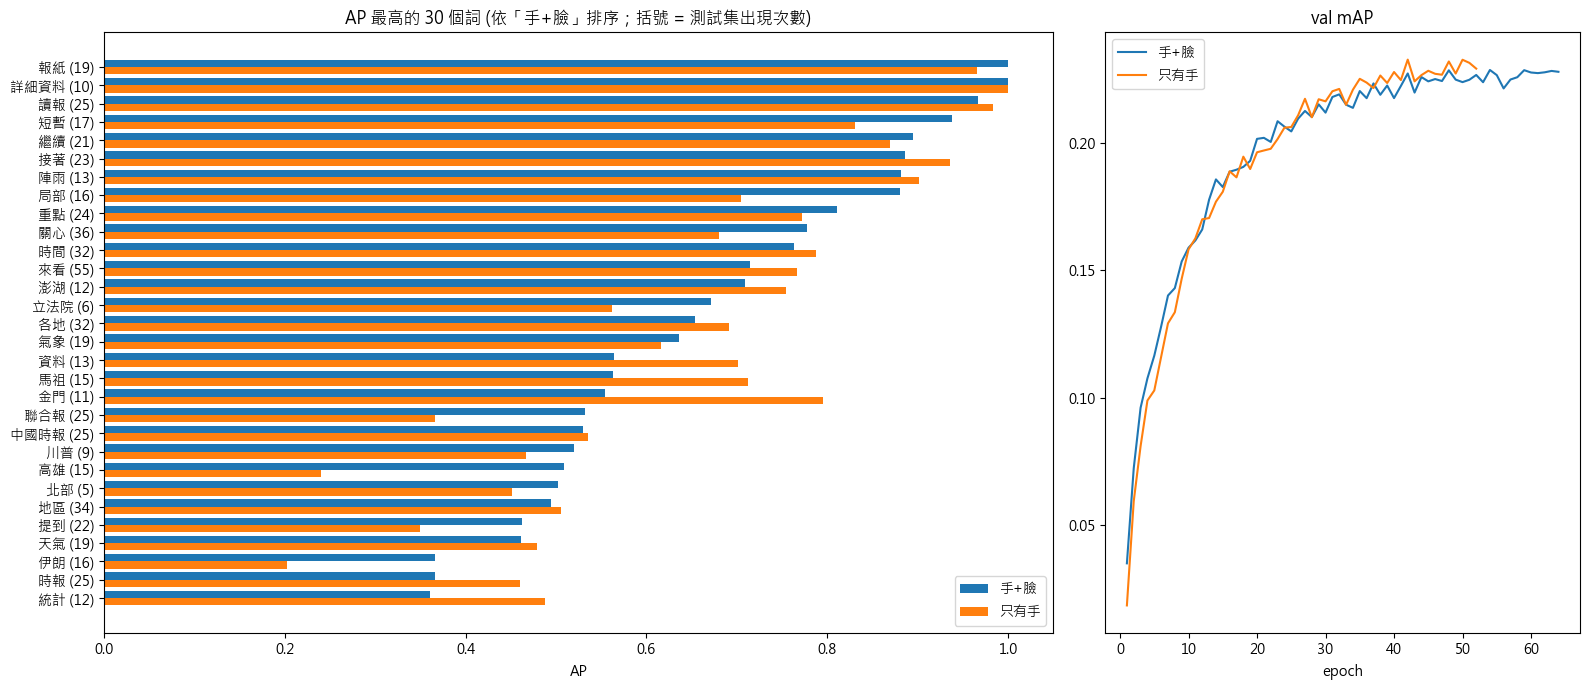

「手+臉」比「只有手」進步最多的詞：
  高雄 (0.24→0.51)、最新 (0.06→0.26)、日前 (0.06→0.26)、局部 (0.70→0.88)、最近 (0.04→0.22)、至少 (0.08→0.25)、聯合報 (0.37→0.53)、伊朗 (0.20→0.37)、國內 (0.16→0.30)、涉嫌 (0.08→0.20)、疑似 (0.03→0.15)、提到 (0.35→0.46)、立法院 (0.56→0.67)、短暫 (0.83→0.94)、關心 (0.68→0.78)


In [10]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

main = names[0]
ap = results[main]["ap"]
order = [j for j in np.argsort(-np.nan_to_num(ap, nan=-1)) if mask[j]]
top = order[:30]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [2, 1]})
y = np.arange(len(top))
for k, name in enumerate(names):
    axes[0].barh(y + k * 0.4, results[name]["ap"][top], height=0.4, label=name)
axes[0].set_yticks(y + 0.2, [f"{KEYWORDS[j]} ({int(labels[:, j].sum())})" for j in top])
axes[0].invert_yaxis()
axes[0].set_xlabel("AP")
axes[0].set_title(f"AP 最高的 30 個詞 (依「{main}」排序；括號 = 測試集出現次數)")
axes[0].legend()

for name in names:
    h = np.array(results[name]["info"]["history"])
    axes[1].plot(np.arange(1, len(h) + 1), h[:, 1], label=name)
axes[1].set_xlabel("epoch")
axes[1].set_title("val mAP")
axes[1].legend()
plt.tight_layout()
plt.show()

if len(names) == 2:
    gain = results[names[0]]["ap"] - results[names[1]]["ap"]
    idx = [j for j in np.argsort(-np.nan_to_num(gain, nan=-9)) if mask[j]][:15]
    print(f"「{names[0]}」比「{names[1]}」進步最多的詞：")
    print("  " + "、".join(f"{KEYWORDS[j]} ({results[names[1]]['ap'][j]:.2f}→{results[names[0]]['ap'][j]:.2f})" for j in idx))

## 範例：模型認為這段手語提到了哪些詞

In [11]:
SHOW = 12       # 顯示幾句
TOP_K = 5       # 每句列出機率最高的幾個詞

scores = results[main]["scores"]
rng = np.random.default_rng(0)
picks = [i for i in rng.permutation(len(labels)) if labels[i].sum() > 0][:SHOW]
for i in picks:
    path, text = test_set.rows[i]
    truth = {KEYWORDS[j] for j in np.flatnonzero(labels[i])}
    top = np.argsort(-scores[i])[:TOP_K]
    guess = "、".join(f"{'✓' if KEYWORDS[j] in truth else ' '}{KEYWORDS[j]}({scores[i, j]:.2f})" for j in top)
    print(f"{text}\n  字幕裡的關鍵詞：{'、'.join(sorted(truth))}\n  模型前 {TOP_K} 名：{guess}\n")

觀光局統計全國旅館的住房率不到5成
  字幕裡的關鍵詞：統計
  模型前 5 名：✓統計(0.90)、 超過(0.61)、 花蓮(0.28)、 國內(0.25)、 億元(0.19)

以及匡列金額沒有共識
  字幕裡的關鍵詞：以及、沒有
  模型前 5 名： 要求(0.63)、✓沒有(0.61)、 回應(0.30)、 立法院(0.19)、 許多(0.16)

彭博資訊報導 拜登政府
  字幕裡的關鍵詞：報導、政府
  模型前 5 名： 活動(0.02)、 伊朗(0.01)、 萬元(0.01)、✓政府(0.01)、 最後(0.01)

私人行程 當天來回沒有其他評論
  字幕裡的關鍵詞：其他、沒有
  模型前 5 名： 造成(0.55)、 宣布(0.51)、 疫情(0.30)、 國內(0.18)、 引發(0.14)

而宜蘭則需留意可能會有超大豪雨
  字幕裡的關鍵詞：可能
  模型前 5 名：✓可能(0.96)、 發生(0.51)、 持續(0.44)、 山區(0.26)、 地區(0.20)

接著來看今天白天詳細溫度預測
  字幕裡的關鍵詞：今天、來看、接著
  模型前 5 名： 提供(1.00)、 資料(1.00)、 氣象(1.00)、✓接著(1.00)、 各地(1.00)

昨天台鐵發生冒煙意外 中午12點55分
  字幕裡的關鍵詞：台鐵、昨天、發生
  模型前 5 名： 傳出(0.92)、✓昨天(0.62)、 事件(0.33)、 表示(0.27)、 最近(0.13)

讀報時間來看到
  字幕裡的關鍵詞：來看、時間、讀報
  模型前 5 名：✓時間(0.99)、✓讀報(0.99)、✓來看(0.99)、 中國時報(0.92)、 台灣(0.00)

還可以根據任務指令實際執行 其中
  字幕裡的關鍵詞：其中、可以、根據
  模型前 5 名： 使用(0.46)、 旅客(0.07)、✓其中(0.06)、 晚間(0.04)、 正式(0.04)

29日舉行台灣日活動
  字幕裡的關鍵詞：台灣、活動、舉行
  模型前 5 名： 總統(0.65)、 以及(0.15)、 公布(0.02)、 昨天(0.02)、 美國(0.02)

最近有詐騙集團盯上退休長輩
  字幕裡的關鍵詞：最近、詐騙、集團
  模型前 5 名：✓最近(0.98)、 近期(0.92)、 日前(0.77)、 

## 怎麼解讀

- **mAP 明顯高於「亂猜」**：模型確實學到了某些詞的手勢
- **mAP 明顯高於「同則打亂 mAP」**：模型辨認的是「這一句」的內容，不只是猜到新聞主題。這是最重要的比較
- **「手+臉」明顯高於「只有手」** (bootstrap 區間不包含 0)：臉部特徵 (嘴型、表情) 對辨認詞有幫助；「進步最多的詞」可以看出是哪些詞受益
- **AP 最高的詞**：模型最有把握的詞，可以用來做展示；AP 很低的詞可以考慮從清單移除，或檢查它們在手語中是否有固定的打法